In [1]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import statsmodels.api as sm

from src.data import *
from src.models import *
from src.features import log_returns, realised_volatility
from src.backtest import walk_forward
from src.metrics import compare_models, compare_models_staggered, dm_table

/opt/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.2' currently installed).
  from pandas.core import (


### ==== Validation =====

In [2]:
spot = load_brent_spot(start="1987-01-01")
data = spot.copy()
data["log_return"] = log_returns(data, col="brent_spot")
data = data.dropna()


val_args = dict(horizon=1, start_date="2024-01-01", end_date="2025-12-31", target_end_date="2025-12-31")


val_results = {
    "Random Walk": walk_forward(data, forecast_funct=random_walk_forecast, **val_args),
    "Historical Mean": walk_forward(data, forecast_funct=historical_mean_forecast, lookback=3000, **val_args),
    "AR": walk_forward(data, forecast_funct=ar1_forecast, lookback=3000, **val_args),
    "Direct Forecast": walk_forward(data, forecast_funct=direct_forecast, lookback=3000, **val_args),
    "Direct Lag_1 Lag_60": walk_forward(data, forecast_funct=direct_lags_forecast, short=1, long=60, lookback=3000, **val_args),
    "Direct Lag_5 Lag_60": walk_forward(data, forecast_funct=direct_lags_forecast, short=5, long=60, lookback=3000, **val_args)
}

compare_models(val_results, horizon=60)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,sharpe_ratio,max_drawdown,num_trades
model,,,,,,,,,,,,,,
Random Walk,1.017925,1.337748,1.373841,0.005929,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.0
Historical Mean,1.018121,1.337821,1.373962,0.501976,0.000000,0.000000,0.000000,0.501976,1.000000,0.668421,-0.012542,-0.383374,-0.034918,1.0
AR,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.008535,0.258169,-0.026683,5.0
Direct Forecast,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.008535,0.258169,-0.026683,5.0
Direct Lag_1 Lag_60,1.017655,1.338184,1.373511,0.488142,0.478723,0.361446,0.411899,0.493711,0.618110,0.548951,0.029255,0.991013,-0.013107,5.0
Direct Lag_5 Lag_60,1.016544,1.336837,1.371741,0.523715,0.528497,0.409639,0.461538,0.520767,0.641732,0.574956,-0.010090,-0.306901,-0.053881,7.0


In [3]:
compare_models_staggered(val_results, horizon=60)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,sharpe_ratio,max_drawdown,avg_gross_exposure,pct_time_net_long,annual_turnover
model,,,,,,,,,,,,,,,,
Random Walk,1.017925,1.337748,1.373841,0.005929,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,0.000000
Historical Mean,1.018121,1.337821,1.373962,0.501976,0.000000,0.000000,0.000000,0.501976,1.000000,0.668421,0.138785,0.472396,-0.263059,1.000000,0.000000,0.000000
AR,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.072907,0.842064,-0.063038,0.291685,0.008989,4.077303
Direct Forecast,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.072907,0.842064,-0.063038,0.291685,0.008989,4.077303
Direct Lag_1 Lag_60,1.017655,1.338184,1.373511,0.488142,0.478723,0.361446,0.411899,0.493711,0.618110,0.548951,0.115786,1.332435,-0.049199,0.269663,0.080899,4.360449
Direct Lag_5 Lag_60,1.016544,1.336837,1.371741,0.523715,0.528497,0.409639,0.461538,0.520767,0.641732,0.574956,0.098252,1.135228,-0.086067,0.251461,0.083146,4.001798


#### Mean Revert

In [4]:
# PRICES = ["brent_spot", "wti", "usd", "sp500"]   # prices -> log returns
# INDICES = ["vix", "ovx", "epu", "gpr"]           # fear/uncertainty indices -> log levels

df_mr = load_dataset()
df_mr = df_mr[["brent_spot", "wti"]]
df_mr = df_mr.rename(columns={"wti": "wti_spot"})
df_mr["log_return"] = np.log(df_mr["brent_spot"]).diff()
df_mr = df_mr.dropna()

df_mr.tail()

,brent_spot,wti_spot,log_return
DATE,,,
2026-10-21,117.37,103.95,0.018488
2026-10-22,125.39,104.27,0.066098
2026-10-23,128.30,109.72,0.022942
2026-10-26,128.12,105.25,-0.001404
2026-10-27,123.10,103.37,-0.039970


In [6]:
val_forecast = walk_forward(df_mr, forecast_funct=spread_mr_forecast, lookback=3000, **val_args)
val_forecast.tail()

,origin_date,target_date,origin_price,forecast,actual
501,2025-12-22,2025-12-23,62.22,62.162044,63.70
502,2025-12-23,2025-12-24,63.70,63.534057,63.70
503,2025-12-24,2025-12-29,63.70,63.552391,63.10
504,2025-12-29,2025-12-30,63.10,62.924637,62.30
505,2025-12-30,2025-12-31,62.30,62.193352,61.35


In [7]:
val_results["Mean Revert"] = val_forecast

compare_models(val_results, horizon=60)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,sharpe_ratio,max_drawdown,num_trades
model,,,,,,,,,,,,,,
Random Walk,1.017925,1.337748,1.373841,0.005929,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.0
Historical Mean,1.018121,1.337821,1.373962,0.501976,0.000000,0.000000,0.000000,0.501976,1.000000,0.668421,-0.012542,-0.383374,-0.034918,1.0
AR,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.008535,0.258169,-0.026683,5.0
Direct Forecast,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.008535,0.258169,-0.026683,5.0
Direct Lag_1 Lag_60,1.017655,1.338184,1.373511,0.488142,0.478723,0.361446,0.411899,0.493711,0.618110,0.548951,0.029255,0.991013,-0.013107,5.0
Direct Lag_5 Lag_60,1.016544,1.336837,1.371741,0.523715,0.528497,0.409639,0.461538,0.520767,0.641732,0.574956,-0.010090,-0.306901,-0.053881,7.0
Mean Revert,1.012017,1.327569,1.366409,0.503953,0.500000,0.710843,0.587065,0.513158,0.307087,0.384236,-0.021133,-0.667783,-0.043405,9.0


In [8]:
compare_models_staggered(val_results, horizon=60)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,sharpe_ratio,max_drawdown,avg_gross_exposure,pct_time_net_long,annual_turnover
model,,,,,,,,,,,,,,,,
Random Walk,1.017925,1.337748,1.373841,0.005929,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,0.000000
Historical Mean,1.018121,1.337821,1.373962,0.501976,0.000000,0.000000,0.000000,0.501976,1.000000,0.668421,0.138785,0.472396,-0.263059,1.000000,0.000000,0.000000
AR,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.072907,0.842064,-0.063038,0.291685,0.008989,4.077303
Direct Forecast,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.072907,0.842064,-0.063038,0.291685,0.008989,4.077303
Direct Lag_1 Lag_60,1.017655,1.338184,1.373511,0.488142,0.478723,0.361446,0.411899,0.493711,0.618110,0.548951,0.115786,1.332435,-0.049199,0.269663,0.080899,4.360449
Direct Lag_5 Lag_60,1.016544,1.336837,1.371741,0.523715,0.528497,0.409639,0.461538,0.520767,0.641732,0.574956,0.098252,1.135228,-0.086067,0.251461,0.083146,4.001798
Mean Revert,1.012017,1.327569,1.366409,0.503953,0.500000,0.710843,0.587065,0.513158,0.307087,0.384236,-0.096780,-0.550160,-0.238300,0.548464,0.858427,3.341124


#### XGBoost

In [9]:
val_forecast = walk_forward(data, forecast_funct=xgb_direct_forecast, lookback=3000, **val_args)
val_forecast.tail()

,origin_date,target_date,origin_price,forecast,actual
501,2025-12-22,2025-12-23,62.22,62.229814,63.70
502,2025-12-23,2025-12-24,63.70,63.713357,63.70
503,2025-12-24,2025-12-29,63.70,63.701865,63.10
504,2025-12-29,2025-12-30,63.10,63.098841,62.30
505,2025-12-30,2025-12-31,62.30,62.303379,61.35


In [10]:
val_results["XGBoost"] = val_forecast

compare_models(val_results, horizon=60)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,sharpe_ratio,max_drawdown,num_trades
model,,,,,,,,,,,,,,
Random Walk,1.017925,1.337748,1.373841,0.005929,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.0
Historical Mean,1.018121,1.337821,1.373962,0.501976,0.000000,0.000000,0.000000,0.501976,1.000000,0.668421,-0.012542,-0.383374,-0.034918,1.0
AR,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.008535,0.258169,-0.026683,5.0
Direct Forecast,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.008535,0.258169,-0.026683,5.0
Direct Lag_1 Lag_60,1.017655,1.338184,1.373511,0.488142,0.478723,0.361446,0.411899,0.493711,0.618110,0.548951,0.029255,0.991013,-0.013107,5.0
Direct Lag_5 Lag_60,1.016544,1.336837,1.371741,0.523715,0.528497,0.409639,0.461538,0.520767,0.641732,0.574956,-0.010090,-0.306901,-0.053881,7.0
Mean Revert,1.012017,1.327569,1.366409,0.503953,0.500000,0.710843,0.587065,0.513158,0.307087,0.384236,-0.021133,-0.667783,-0.043405,9.0
XGBoost,1.022330,1.343937,1.380448,0.486166,0.488223,0.915663,0.636872,0.461538,0.070866,0.122867,0.012449,0.380871,-0.020497,1.0


In [11]:
compare_models_staggered(val_results, horizon=60)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,sharpe_ratio,max_drawdown,avg_gross_exposure,pct_time_net_long,annual_turnover
model,,,,,,,,,,,,,,,,
Random Walk,1.017925,1.337748,1.373841,0.005929,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,0.000000
Historical Mean,1.018121,1.337821,1.373962,0.501976,0.000000,0.000000,0.000000,0.501976,1.000000,0.668421,0.138785,0.472396,-0.263059,1.000000,0.000000,0.000000
AR,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.072907,0.842064,-0.063038,0.291685,0.008989,4.077303
Direct Forecast,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.072907,0.842064,-0.063038,0.291685,0.008989,4.077303
Direct Lag_1 Lag_60,1.017655,1.338184,1.373511,0.488142,0.478723,0.361446,0.411899,0.493711,0.618110,0.548951,0.115786,1.332435,-0.049199,0.269663,0.080899,4.360449
Direct Lag_5 Lag_60,1.016544,1.336837,1.371741,0.523715,0.528497,0.409639,0.461538,0.520767,0.641732,0.574956,0.098252,1.135228,-0.086067,0.251461,0.083146,4.001798
Mean Revert,1.012017,1.327569,1.366409,0.503953,0.500000,0.710843,0.587065,0.513158,0.307087,0.384236,-0.096780,-0.550160,-0.238300,0.548464,0.858427,3.341124
XGBoost,1.022330,1.343937,1.380448,0.486166,0.488223,0.915663,0.636872,0.461538,0.070866,0.122867,-0.142940,-0.565592,-0.337045,0.869363,1.000000,1.170337


#### Direct Ridge Forecast

In [12]:
df_rr = load_dataset()
  
df_rr = df_rr[["brent_spot", "wti", "usd", "sp500", "vix", "ovx"]]
df_rr = df_rr.rename(columns={"wti": "wti_spot"})
df_rr = df_rr.dropna()

for col in ["usd", "sp500", "vix", "ovx"]:
    df_rr[col] = np.log(df_rr[col])

df_rr.tail()

,brent_spot,wti_spot,usd,sp500,vix,ovx
DATE,,,,,,
2026-10-21,117.37,103.95,4.798615,8.956373,2.814210,3.975561
2026-10-22,125.39,104.27,4.798704,8.944215,2.946017,4.018902
2026-10-23,128.30,109.72,4.798433,8.939014,2.967847,4.094678
2026-10-26,128.12,105.25,4.798433,8.945954,2.911807,4.072610
2026-10-27,123.10,103.37,4.798433,8.951906,2.863343,4.015301


In [13]:
val_forecast = walk_forward(df_rr, forecast_funct=direct_ridge_forecast, lookback=3000, **val_args)
val_forecast.tail()

,origin_date,target_date,origin_price,forecast,actual
501,2025-12-22,2025-12-23,62.22,62.281743,63.70
502,2025-12-23,2025-12-24,63.70,63.659620,63.70
503,2025-12-24,2025-12-29,63.70,63.680214,63.10
504,2025-12-29,2025-12-30,63.10,63.035693,62.30
505,2025-12-30,2025-12-31,62.30,62.303057,61.35


In [14]:
val_results["Direct Ridge"] = val_forecast

compare_models(val_results,  horizon=60)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,sharpe_ratio,max_drawdown,num_trades
model,,,,,,,,,,,,,,
Random Walk,1.017925,1.337748,1.373841,0.005929,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.0
Historical Mean,1.018121,1.337821,1.373962,0.501976,0.000000,0.000000,0.000000,0.501976,1.000000,0.668421,-0.012542,-0.383374,-0.034918,1.0
AR,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.008535,0.258169,-0.026683,5.0
Direct Forecast,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.008535,0.258169,-0.026683,5.0
Direct Lag_1 Lag_60,1.017655,1.338184,1.373511,0.488142,0.478723,0.361446,0.411899,0.493711,0.618110,0.548951,0.029255,0.991013,-0.013107,5.0
Direct Lag_5 Lag_60,1.016544,1.336837,1.371741,0.523715,0.528497,0.409639,0.461538,0.520767,0.641732,0.574956,-0.010090,-0.306901,-0.053881,7.0
Mean Revert,1.012017,1.327569,1.366409,0.503953,0.500000,0.710843,0.587065,0.513158,0.307087,0.384236,-0.021133,-0.667783,-0.043405,9.0
XGBoost,1.022330,1.343937,1.380448,0.486166,0.488223,0.915663,0.636872,0.461538,0.070866,0.122867,0.012449,0.380871,-0.020497,1.0
Direct Ridge,1.005928,1.330370,1.356872,0.563241,0.545171,0.702811,0.614035,0.594595,0.433071,0.501139,-0.000153,-0.004605,-0.043405,7.0


In [15]:
compare_models_staggered(val_results, horizon=60)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,sharpe_ratio,max_drawdown,avg_gross_exposure,pct_time_net_long,annual_turnover
model,,,,,,,,,,,,,,,,
Random Walk,1.017925,1.337748,1.373841,0.005929,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,0.000000
Historical Mean,1.018121,1.337821,1.373962,0.501976,0.000000,0.000000,0.000000,0.501976,1.000000,0.668421,0.138785,0.472396,-0.263059,1.000000,0.000000,0.000000
AR,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.072907,0.842064,-0.063038,0.291685,0.008989,4.077303
Direct Forecast,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.072907,0.842064,-0.063038,0.291685,0.008989,4.077303
Direct Lag_1 Lag_60,1.017655,1.338184,1.373511,0.488142,0.478723,0.361446,0.411899,0.493711,0.618110,0.548951,0.115786,1.332435,-0.049199,0.269663,0.080899,4.360449
Direct Lag_5 Lag_60,1.016544,1.336837,1.371741,0.523715,0.528497,0.409639,0.461538,0.520767,0.641732,0.574956,0.098252,1.135228,-0.086067,0.251461,0.083146,4.001798
Mean Revert,1.012017,1.327569,1.366409,0.503953,0.500000,0.710843,0.587065,0.513158,0.307087,0.384236,-0.096780,-0.550160,-0.238300,0.548464,0.858427,3.341124
XGBoost,1.022330,1.343937,1.380448,0.486166,0.488223,0.915663,0.636872,0.461538,0.070866,0.122867,-0.142940,-0.565592,-0.337045,0.869363,1.000000,1.170337
Direct Ridge,1.005928,1.330370,1.356872,0.563241,0.545171,0.702811,0.614035,0.594595,0.433071,0.501139,-0.049513,-0.334330,-0.176567,0.489888,0.707865,4.926742


#### Combination Forecast

In [16]:
weights = [0.1, 0.35, 0.2, 0.35]
val_forecast = walk_forward(data, forecast_funct=combination_forecast, weights=weights, **val_args)
val_forecast.tail()

,origin_date,target_date,origin_price,forecast,actual
501,2025-12-22,2025-12-23,62.22,62.203496,63.70
502,2025-12-23,2025-12-24,63.70,63.677639,63.70
503,2025-12-24,2025-12-29,63.70,63.692384,63.10
504,2025-12-29,2025-12-30,63.10,63.098424,62.30
505,2025-12-30,2025-12-31,62.30,62.301436,61.35


In [17]:
val_results["Combination"] = val_forecast

compare_models(val_results, horizon=60)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,sharpe_ratio,max_drawdown,num_trades
model,,,,,,,,,,,,,,
Random Walk,1.017925,1.337748,1.373841,0.005929,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.0
Historical Mean,1.018121,1.337821,1.373962,0.501976,0.000000,0.000000,0.000000,0.501976,1.000000,0.668421,-0.012542,-0.383374,-0.034918,1.0
AR,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.008535,0.258169,-0.026683,5.0
Direct Forecast,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.008535,0.258169,-0.026683,5.0
Direct Lag_1 Lag_60,1.017655,1.338184,1.373511,0.488142,0.478723,0.361446,0.411899,0.493711,0.618110,0.548951,0.029255,0.991013,-0.013107,5.0
Direct Lag_5 Lag_60,1.016544,1.336837,1.371741,0.523715,0.528497,0.409639,0.461538,0.520767,0.641732,0.574956,-0.010090,-0.306901,-0.053881,7.0
Mean Revert,1.012017,1.327569,1.366409,0.503953,0.500000,0.710843,0.587065,0.513158,0.307087,0.384236,-0.021133,-0.667783,-0.043405,9.0
XGBoost,1.022330,1.343937,1.380448,0.486166,0.488223,0.915663,0.636872,0.461538,0.070866,0.122867,0.012449,0.380871,-0.020497,1.0
Direct Ridge,1.005928,1.330370,1.356872,0.563241,0.545171,0.702811,0.614035,0.594595,0.433071,0.501139,-0.000153,-0.004605,-0.043405,7.0


In [18]:
compare_models_staggered(val_results, horizon=60)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,sharpe_ratio,max_drawdown,avg_gross_exposure,pct_time_net_long,annual_turnover
model,,,,,,,,,,,,,,,,
Random Walk,1.017925,1.337748,1.373841,0.005929,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,0.000000
Historical Mean,1.018121,1.337821,1.373962,0.501976,0.000000,0.000000,0.000000,0.501976,1.000000,0.668421,0.138785,0.472396,-0.263059,1.000000,0.000000,0.000000
AR,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.072907,0.842064,-0.063038,0.291685,0.008989,4.077303
Direct Forecast,1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,0.072907,0.842064,-0.063038,0.291685,0.008989,4.077303
Direct Lag_1 Lag_60,1.017655,1.338184,1.373511,0.488142,0.478723,0.361446,0.411899,0.493711,0.618110,0.548951,0.115786,1.332435,-0.049199,0.269663,0.080899,4.360449
Direct Lag_5 Lag_60,1.016544,1.336837,1.371741,0.523715,0.528497,0.409639,0.461538,0.520767,0.641732,0.574956,0.098252,1.135228,-0.086067,0.251461,0.083146,4.001798
Mean Revert,1.012017,1.327569,1.366409,0.503953,0.500000,0.710843,0.587065,0.513158,0.307087,0.384236,-0.096780,-0.550160,-0.238300,0.548464,0.858427,3.341124
XGBoost,1.022330,1.343937,1.380448,0.486166,0.488223,0.915663,0.636872,0.461538,0.070866,0.122867,-0.142940,-0.565592,-0.337045,0.869363,1.000000,1.170337
Direct Ridge,1.005928,1.330370,1.356872,0.563241,0.545171,0.702811,0.614035,0.594595,0.433071,0.501139,-0.049513,-0.334330,-0.176567,0.489888,0.707865,4.926742


### ==== Diebold-Mariano test ====

In [19]:
for loss in ["ae", "se"]:
    print(f"\nDM test vs Random Walk, loss = {loss}")
    print(dm_table(val_results, benchmark="Random Walk", horizon=60, loss=loss).round(4))


DM test vs Random Walk, loss = ae
                     DM_stat  p_value      n
Historical Mean       0.3666   0.7141  506.0
AR                    1.7198   0.0861  506.0
Direct Forecast       1.7198   0.0861  506.0
Direct Lag_1 Lag_60   0.5569   0.5778  506.0
Direct Lag_5 Lag_60  -0.7061   0.4805  506.0
Mean Revert              NaN      NaN  506.0
XGBoost               2.0380   0.0421  506.0
Direct Ridge         -3.1998   0.0015  506.0
Combination           1.6558   0.0984  506.0

DM test vs Random Walk, loss = se
                     DM_stat  p_value      n
Historical Mean       0.3666   0.7141  506.0
AR                    1.7198   0.0861  506.0
Direct Forecast       1.7198   0.0861  506.0
Direct Lag_1 Lag_60   0.5569   0.5778  506.0
Direct Lag_5 Lag_60  -0.7061   0.4805  506.0
Mean Revert              NaN      NaN  506.0
XGBoost               2.0380   0.0421  506.0
Direct Ridge         -3.1998   0.0015  506.0
Combination           1.6558   0.0984  506.0


/Users/Home/Documents/Sample-Taxed/notebooks/../src/metrics.py:106: RuntimeWarning: invalid value encountered in sqrt
  dm_stat = d.mean() / np.sqrt(variance / n) # like a t-stat: average gap / its standard error
/Users/Home/Documents/Sample-Taxed/notebooks/../src/metrics.py:106: RuntimeWarning: invalid value encountered in sqrt
  dm_stat = d.mean() / np.sqrt(variance / n) # like a t-stat: average gap / its standard error


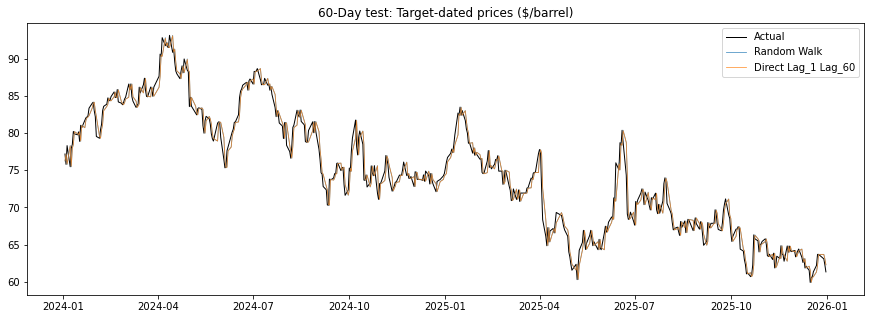

In [31]:
plt.figure(figsize=(15, 5))
plt.plot(np.array(val_results["Random Walk"]["target_date"]), np.array(val_results["Random Walk"]["actual"]), label='Actual', color='black', lw=1)

for name in ["Random Walk", "Direct Lag_1 Lag_60"]:
    r = val_results[name]
    plt.plot(np.array(r["target_date"]), np.array(r["forecast"]), label=name, alpha=0.8, lw=0.8)

plt.title("60-Day test: Target-dated prices ($/barrel)")
plt.legend(loc="upper right")
plt.show()

### ==== Test ====

In [22]:
test_args = dict(horizon=60, start_date="2026-01-01", end_date="2026-09-30", target_end_date="2026-09-30")

test_results = {
    "Random Walk": walk_forward(data, forecast_funct=random_walk_forecast, **test_args),
    "Historical Mean": walk_forward(data, forecast_funct=historical_mean_forecast, lookback=3000, **test_args),
    "AR": walk_forward(data, forecast_funct=ar1_forecast, lookback=3000, **test_args),
    "Direct Forecast": walk_forward(data, forecast_funct=direct_forecast, lookback=3000, **test_args),
    "Direct Lag_1 Lag_60": walk_forward(data, forecast_funct=direct_lags_forecast, short=1, long=60, lookback=3000, **test_args),
    "Direct Lag_5 Lag_60": walk_forward(data, forecast_funct=direct_lags_forecast, short=5, long=60, lookback=3000, **test_args),
    "Mean Revert": walk_forward(df_mr, forecast_funct=spread_mr_forecast, lookback=3000, **test_args),
    "XGBoost": walk_forward(data, forecast_funct=xgb_direct_forecast, lookback=3000, **test_args),
    "Direct Ridge": walk_forward(df_rr, forecast_funct=direct_ridge_forecast, lookback=3000, **test_args),
    "Combination": walk_forward(data, forecast_funct=combination_forecast, weights=weights, **test_args)
}

compare_models(test_results, horizon=60)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,sharpe_ratio,max_drawdown,num_trades
model,,,,,,,,,,,,,,
Random Walk,32.663333,37.088322,32.955882,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.0
Historical Mean,32.970212,37.448324,33.241586,0.178295,0.000000,0.000000,0.000000,0.244681,0.396552,0.302632,-2.766387,-4.735027,-0.771169,5.0
AR,32.969282,37.443084,33.240413,0.170543,0.000000,0.000000,0.000000,0.236559,0.379310,0.291391,-2.766387,-4.735027,-0.771169,5.0
Direct Forecast,26.784257,32.426083,25.841311,0.635659,1.000000,0.338028,0.505263,0.552381,1.000000,0.711656,2.764987,4.730877,0.000000,5.0
Direct Lag_1 Lag_60,26.469949,32.113053,25.588352,0.627907,1.000000,0.323944,0.489362,0.547170,1.000000,0.707317,2.764987,4.730877,0.000000,5.0
Direct Lag_5 Lag_60,26.456992,32.120494,25.550504,0.612403,0.920000,0.323944,0.479167,0.538462,0.965517,0.691358,2.764987,4.730877,0.000000,5.0
Mean Revert,30.728036,35.471597,30.230755,0.472868,0.533333,0.338028,0.413793,0.440476,0.637931,0.521127,0.077755,0.044370,0.000000,3.0
XGBoost,37.767243,42.116770,39.954089,0.480620,0.516667,0.873239,0.649215,0.000000,0.000000,0.000000,-1.022467,-0.622183,-0.393137,3.0
Direct Ridge,32.530561,37.042527,32.801530,0.612403,0.723404,0.478873,0.576271,0.548780,0.775862,0.642857,1.021627,0.621770,-0.622729,3.0


In [23]:
compare_models_staggered(test_results, horizon=60)

,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,sharpe_ratio,max_drawdown,avg_gross_exposure,pct_time_net_long,annual_turnover
model,,,,,,,,,,,,,,,,
Random Walk,32.663333,37.088322,32.955882,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,0.000000
Historical Mean,32.970212,37.448324,33.241586,0.178295,0.000000,0.000000,0.000000,0.244681,0.396552,0.302632,-0.236307,-0.793849,-0.126796,0.256863,0.397059,5.311765
AR,32.969282,37.443084,33.240413,0.170543,0.000000,0.000000,0.000000,0.236559,0.379310,0.291391,-0.263378,-0.942237,-0.127746,0.246569,0.426471,5.435294
Direct Forecast,26.784257,32.426083,25.841311,0.635659,1.000000,0.338028,0.505263,0.552381,1.000000,0.711656,1.567296,2.423684,-0.215947,0.903922,0.000000,2.841176
Direct Lag_1 Lag_60,26.469949,32.113053,25.588352,0.627907,1.000000,0.323944,0.489362,0.547170,1.000000,0.707317,1.568969,2.422993,-0.215947,0.905392,0.000000,2.717647
Direct Lag_5 Lag_60,26.456992,32.120494,25.550504,0.612403,0.920000,0.323944,0.479167,0.538462,0.965517,0.691358,1.494124,2.324436,-0.215947,0.883333,0.000000,2.964706
Mean Revert,30.728036,35.471597,30.230755,0.472868,0.533333,0.338028,0.413793,0.440476,0.637931,0.521127,0.546368,1.039246,-0.196157,0.561765,0.161765,4.694118
XGBoost,37.767243,42.116770,39.954089,0.480620,0.516667,0.873239,0.649215,0.000000,0.000000,0.000000,-1.703112,-2.684098,-0.489858,0.973529,1.000000,1.111765
Direct Ridge,32.530561,37.042527,32.801530,0.612403,0.723404,0.478873,0.576271,0.548780,0.775862,0.642857,0.810825,4.385575,-0.032892,0.298039,0.294118,3.582353


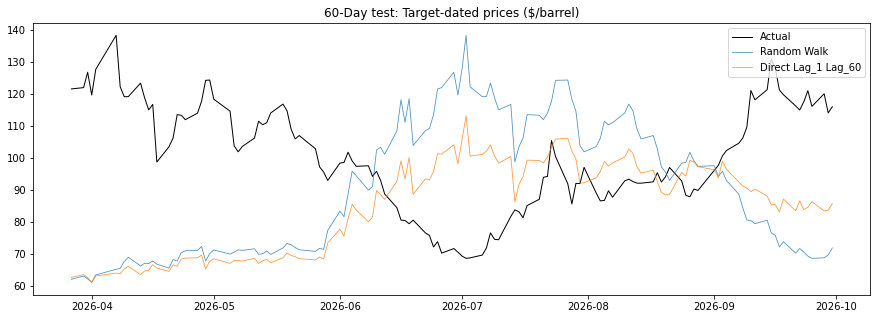

In [28]:
plt.figure(figsize=(15, 5))
plt.plot(np.array(test_results["Random Walk"]["target_date"]), np.array(test_results["Random Walk"]["actual"]), label='Actual', color='black', lw=1)

for name in ["Random Walk", "Direct Lag_1 Lag_60"]:
    r = test_results[name]
    plt.plot(np.array(r["target_date"]), np.array(r["forecast"]), label=name, alpha=0.8, lw=0.8)

plt.title("60-Day test: Target-dated prices ($/barrel)")
plt.legend(loc="upper right")
plt.show()

### ==== Final 60-day forecast =====
origin = 2026-09-30

In [ ]:
from src.final_forecast import direct_report, final_forecast, make_model

# Direct forecast with the OLS table, parameter CI and prediction interval 
# final_forecast = direct_report(data, horizon=60, origin_date="2026-09-30", lookback=3000)

# Model with a GARCH interval
# Switching models: "direct", "direct_lags", "xgboost", "combination" or "random_walk"
final = final_forecast(data, make_model("direct_lags", 60, lookbakc=3000), horizon=60, origin_date="2026-09-30")

Origin 2026-09-30   price = 115.91
Horizon: 60 trading days  (target ~ 2026-12-23)
Predicted 60-day log return = -0.1532
Point forecast : 99.44   (random walk: 115.91)
95% prediction interval (garch): 62.54 to 158.12

19 trading days elapsed. Latest 2026-10-27: 123.10 (realised log return +0.0602)


In [29]:
df_rr["log_return"] = np.log(df_rr["brent_spot"]).diff()
df_rr = df_rr.dropna()
final = final_forecast(df_rr, partial(direct_ridge_forecast, lookback=3000), horizon=60, origin_date="2026-09-30")

Origin 2026-09-30   price = 115.91
Horizon: 60 trading days  (target ~ 2026-12-23)
Predicted 60-day log return = -0.0062
Point forecast : 115.20   (random walk: 115.91)
95% prediction interval (garch): 72.44 to 183.18

19 trading days elapsed. Latest 2026-10-27: 123.10 (realised log return +0.0602)
